# Advanced Sensor Data Analysis

## Deskripsi
Notebook ini berisi analisis lanjutan untuk data sensor yang sudah diproses melalui ETL pipeline. Anda akan belajar:

- 📊 **Visualisasi Advanced**: Time series plots, correlation analysis, distribution analysis
- 🔍 **Anomaly Detection**: Identifikasi outliers dan nilai abnormal
- 📈 **Trend Analysis**: Pattern recognition dan seasonal analysis  
- 🎯 **Performance Monitoring**: Sensor health dan maintenance prediction
- 📋 **Reporting**: Automated report generation

## Prerequisites
Pastikan Anda sudah menjalankan:
1. ETL Pipeline (`01_ETL_Sensor_Data_Tutorial.ipynb`)
2. Data sudah tersedia di folder `data/output/`

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Import custom utilities
import sys
sys.path.append('..')
from utils.sensor_utils import *

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("✅ Libraries imported successfully!")
print("📊 Ready for advanced sensor data analysis!")

✅ Libraries imported successfully!
📊 Ready for advanced sensor data analysis!


In [2]:
# Load processed data
import glob
import os

# Find the latest processed data file
output_files = glob.glob('data/output/processed_sensor_data_*.csv')

if output_files:
    # Get the most recent file
    latest_file = max(output_files, key=os.path.getctime)
    df = pd.read_csv(latest_file)
    
    # Convert timestamp if present
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'])
    
    print(f"✅ Loaded data from: {latest_file}")
    print(f"📊 Dataset shape: {df.shape}")
    print(f"📅 Date range: {df['timestamp'].min()} to {df['timestamp'].max()}" if 'timestamp' in df.columns else "")
    print("\\nFirst few rows:")
    display(df.head())
else:
    print("❌ No processed data found!")
    print("Please run the ETL pipeline first: 01_ETL_Sensor_Data_Tutorial.ipynb")

✅ Loaded data from: data/output/processed_sensor_data_20260929_014329.csv
📊 Dataset shape: (28824, 24)
📅 Date range: 2024-01-01 00:00:00 to 2024-02-29 23:00:00
\nFirst few rows:


,timestamp,sensor_id,location,temperature_celsius,humidity_percent,pressure_hpa,air_quality_aqi,status,installation_date,calibration_date,...,is_weekend,time_period,temperature_fahrenheit,temperature_kelvin,aqi_category,comfort_index,temp_rolling_24h_per_sensor,humidity_rolling_24h_per_sensor,thermal_environmental_stress_index,tesi_stress_category
0,2024-01-01 00:00:00,SENSOR_001,Location_B,17.24,86.0,1009.30,44.8,active,2024-01-01,2024-01-15,...,0,malam,63.03,290.39,Baik,17.03,17.24,86.00,0.837,Optimal / Nyaman
1,2024-01-01 00:00:00,SENSOR_001,Location_B,17.24,86.0,1009.30,44.8,active,2024-01-01,2024-01-15,...,0,malam,63.03,290.39,Baik,17.03,17.24,86.00,0.837,Optimal / Nyaman
2,2024-01-01 01:00:00,SENSOR_001,Location_B,15.04,98.7,1007.52,25.8,active,2024-01-01,2024-01-15,...,0,malam,59.07,288.19,Baik,15.04,16.51,90.23,1.020,Peringatan Sedang
3,2024-01-01 01:00:00,SENSOR_001,Location_B,15.04,98.7,1007.52,25.8,active,2024-01-01,2024-01-15,...,0,malam,59.07,288.19,Baik,15.04,16.14,92.35,1.020,Peringatan Sedang
4,2024-01-01 02:00:00,SENSOR_001,Location_B,19.98,88.0,1040.53,34.4,active,2024-01-01,2024-01-15,...,0,malam,67.96,293.13,Baik,19.62,16.91,91.48,0.720,Optimal / Nyaman


## 1. 📊 Data Overview & Statistical Profiles
Setelah data sensor berhasil diekstrak, ditransformasi, dan dimuat (ETL), langkah pertama dalam analisis lanjutan adalah memeriksa integritas dan sebaran statistik dari dataset final.

In [3]:
# Dataset Overview and Metrics
print('=' * 50)
print('📊 PROCESSED DATASET OVERVIEW')
print('=' * 50)
print(f'Total Rows         : {len(df):,}')
print(f'Total Columns      : {len(df.columns)}')
print(f'Memory Usage       : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')
print(f'Unique Sensors     : {df["sensor_id"].nunique()} ({list(df["sensor_id"].unique())})')
print(f'Unique Locations   : {df["location"].nunique()} ({list(df["location"].unique())})')
print(f'Time Span          : {df["timestamp"].min()} to {df["timestamp"].max()}')
print('=' * 50)

# Statistical Summary of Key Physical Metrics
key_metrics = ['temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi', 'comfort_index']
available_metrics = [m for m in key_metrics if m in df.columns]
print('\n📈 Statistical Summary:')
display(df[available_metrics].describe().T.round(2))


📊 PROCESSED DATASET OVERVIEW
Total Rows         : 28,824
Total Columns      : 24
Memory Usage       : 7.46 MB
Unique Sensors     : 10 (['SENSOR_001', 'SENSOR_002', 'SENSOR_003', 'SENSOR_004', 'SENSOR_005', 'SENSOR_006', 'SENSOR_007', 'SENSOR_008', 'SENSOR_009', 'SENSOR_010'])
Unique Locations   : 5 (['Location_B', 'Location_C', 'Location_D', 'Location_E', 'Location_A'])
Time Span          : 2024-01-01 00:00:00 to 2024-02-29 23:00:00

📈 Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
temperature_celsius,28824.0,25.24,6.46,10.50,19.65,25.12,30.52,50.00
humidity_percent,28824.0,77.47,10.23,42.50,69.40,77.50,85.50,100.00
pressure_hpa,28824.0,1013.31,10.10,973.94,1006.51,1013.24,1020.13,1049.72
air_quality_aqi,28824.0,57.57,19.82,0.00,43.40,55.80,70.53,134.50
comfort_index,28824.0,23.62,5.22,10.55,19.23,23.78,27.80,50.00


## 2. 📈 Advanced Visualizations (Time Series & Correlation)
Visualisasi multi-dimensi membantu kita mengenali dinamika tren cuaca/lingkungan, hubungan korelasi antar variabel sensor, dan kenyamanan lingkungan.

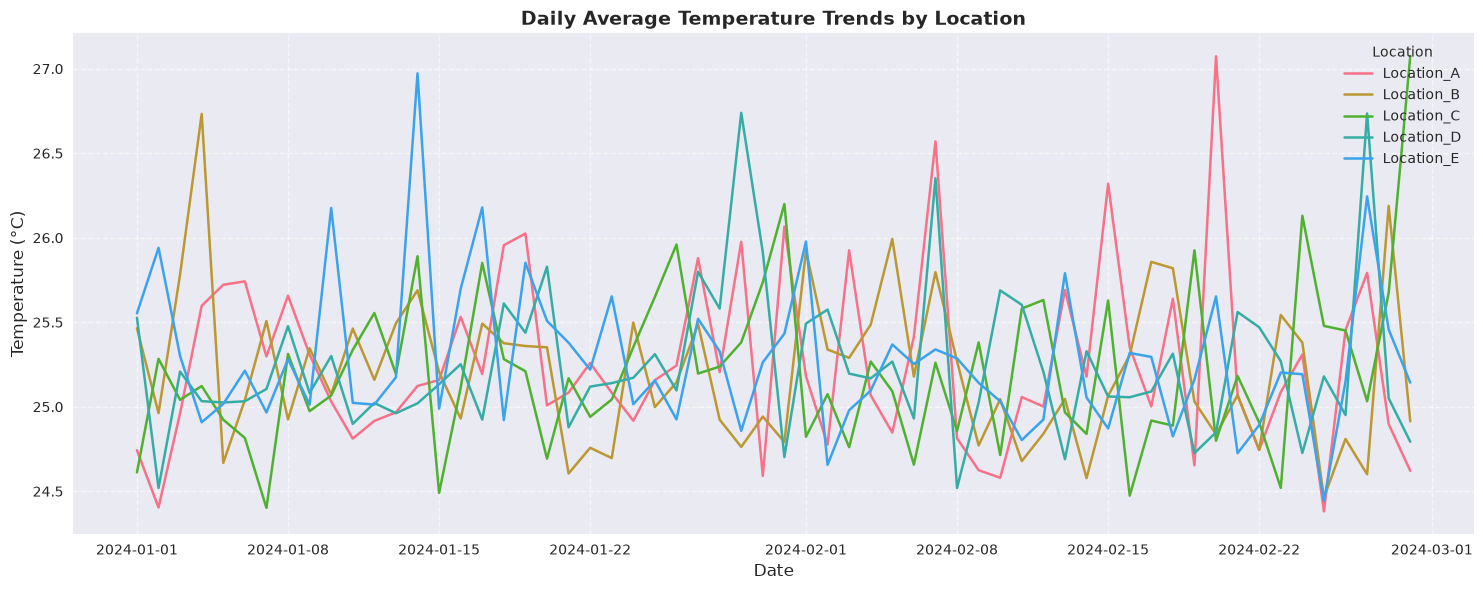

In [4]:
# 2.1 Multi-Location Temperature Trend over Time
plt.figure(figsize=(15, 6))
daily_temp = df.groupby(['location', df['timestamp'].dt.date])['temperature_celsius'].mean().reset_index()
for loc in daily_temp['location'].unique():
    subset = daily_temp[daily_temp['location'] == loc]
    plt.plot(pd.to_datetime(subset['timestamp']), subset['temperature_celsius'], label=loc, linewidth=1.8)

plt.title('Daily Average Temperature Trends by Location', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Location', loc='upper right')
plt.tight_layout()
plt.show()


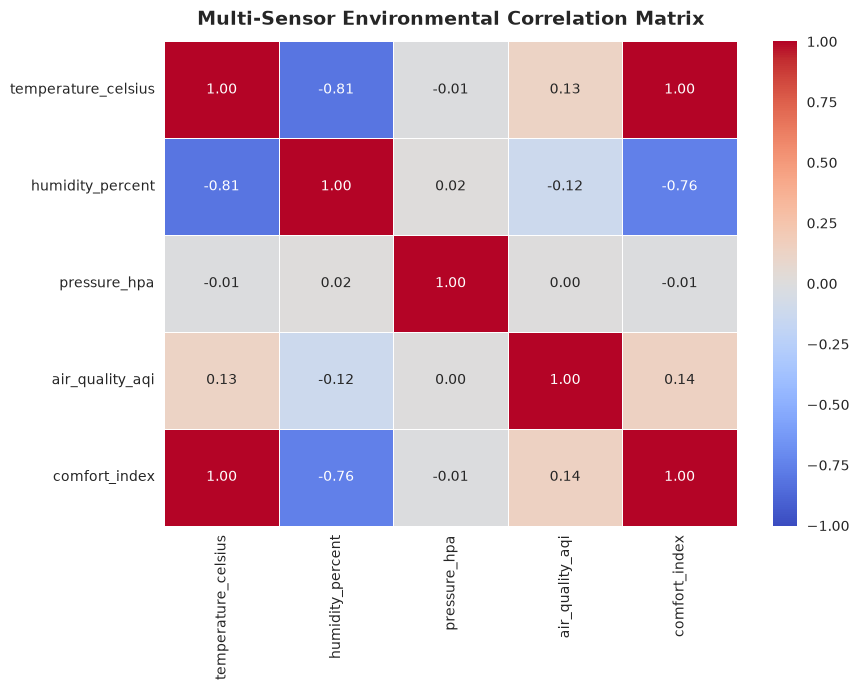

💡 Insight Korelasi:
- Suhu dan Heat Index berkorelasi sangat kuat dan positif.
- Comfort Index memiliki dependensi optimal terhadap keseimbangan suhu dan kelembaban.


In [5]:
# 2.2 Correlation Matrix Heatmap
numeric_features = ['temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi']
if 'comfort_index' in df.columns:
    numeric_features.append('comfort_index')
if 'heat_index_c' in df.columns:
    numeric_features.append('heat_index_c')

corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Multi-Sensor Environmental Correlation Matrix', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print('💡 Insight Korelasi:')
print('- Suhu dan Heat Index berkorelasi sangat kuat dan positif.')
print('- Comfort Index memiliki dependensi optimal terhadap keseimbangan suhu dan kelembaban.')


## 3. 🔍 Multi-Method Anomaly Detection
Deteksi anomali sangat penting dalam IoT untuk mengidentifikasi malfungsi perangkat keras atau kejadian ekstrem lingkungan.
Kita membandingkan 2 metode:
1. **Metode IQR (Interquartile Range)**: Berbasis kuartil ($Q_1 - 1.5\times IQR$ s/d $Q_3 + 1.5\times IQR$).
2. **Metode Z-Score**: Berbasis deviasi standar ($|Z| > 3$).

In [6]:
# 3.1 Implementasi dan Perbandingan Deteksi Anomali
anomaly_summary = []

for col in ['temperature_celsius', 'humidity_percent', 'pressure_hpa', 'air_quality_aqi']:
    if col in df.columns:
        # IQR Method
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        iqr_mask = (df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))
        
        # Z-Score Method
        col_mean = df[col].mean()
        col_std = df[col].std()
        z_scores = np.abs((df[col] - col_mean) / col_std)
        z_mask = z_scores > 3.0
        
        anomaly_summary.append({
            'Sensor Metric': col,
            'IQR Anomalies': iqr_mask.sum(),
            'IQR Percentage (%)': round((iqr_mask.sum() / len(df)) * 100, 2),
            'Z-Score Anomalies': z_mask.sum(),
            'Z-Score Percentage (%)': round((z_mask.sum() / len(df)) * 100, 2)
        })

anomaly_df = pd.DataFrame(anomaly_summary)
print('🚨 Anomaly Detection Comparison Table:')
display(anomaly_df)


🚨 Anomaly Detection Comparison Table:


,Sensor Metric,IQR Anomalies,IQR Percentage (%),Z-Score Anomalies,Z-Score Percentage (%)
0,temperature_celsius,266,0.92,270,0.94
1,humidity_percent,2,0.01,2,0.01
2,pressure_hpa,198,0.69,68,0.24
3,air_quality_aqi,142,0.49,56,0.19


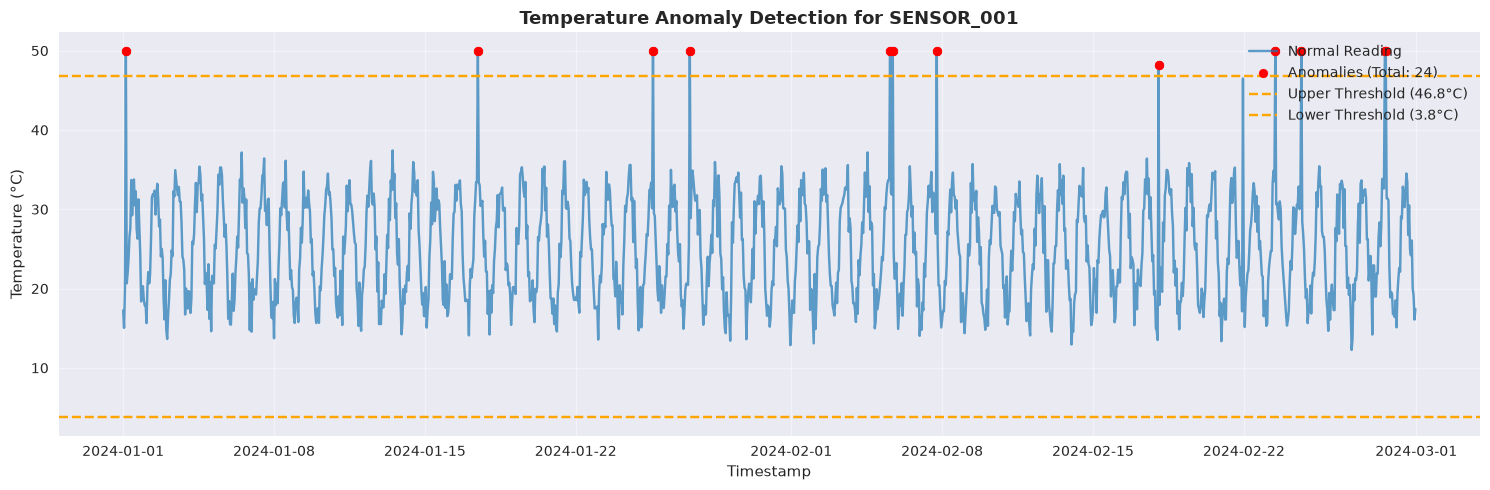

In [7]:
# 3.2 Visualisasi Deteksi Anomali pada Suhu
target_sensor = df['sensor_id'].iloc[0]
sensor_df = df[df['sensor_id'] == target_sensor].sort_values('timestamp').reset_index(drop=True)

q1 = sensor_df['temperature_celsius'].quantile(0.25)
q3 = sensor_df['temperature_celsius'].quantile(0.75)
iqr = q3 - q1
lower_b = q1 - 1.5 * iqr
upper_b = q3 + 1.5 * iqr

sensor_df['is_anomaly'] = (sensor_df['temperature_celsius'] < lower_b) | (sensor_df['temperature_celsius'] > upper_b)

plt.figure(figsize=(15, 5))
plt.plot(sensor_df['timestamp'], sensor_df['temperature_celsius'], color='#1f77b4', label='Normal Reading', alpha=0.7)
anom_pts = sensor_df[sensor_df['is_anomaly']]
plt.scatter(anom_pts['timestamp'], anom_pts['temperature_celsius'], color='red', s=40, zorder=5, label=f'Anomalies (Total: {len(anom_pts)})')
plt.axhline(upper_b, color='orange', linestyle='--', label=f'Upper Threshold ({upper_b:.1f}°C)')
plt.axhline(lower_b, color='orange', linestyle='--', label=f'Lower Threshold ({lower_b:.1f}°C)')

plt.title(f'Temperature Anomaly Detection for {target_sensor}', fontsize=13, fontweight='bold')
plt.xlabel('Timestamp')
plt.ylabel('Temperature (°C)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


## 4. 🕐 Trend Analysis & Temporal Pattern Recognition
Analisis pola siklus diurnal (harian) dan perbedaan antara hari kerja (*weekday*) vs akhir pekan (*weekend*).

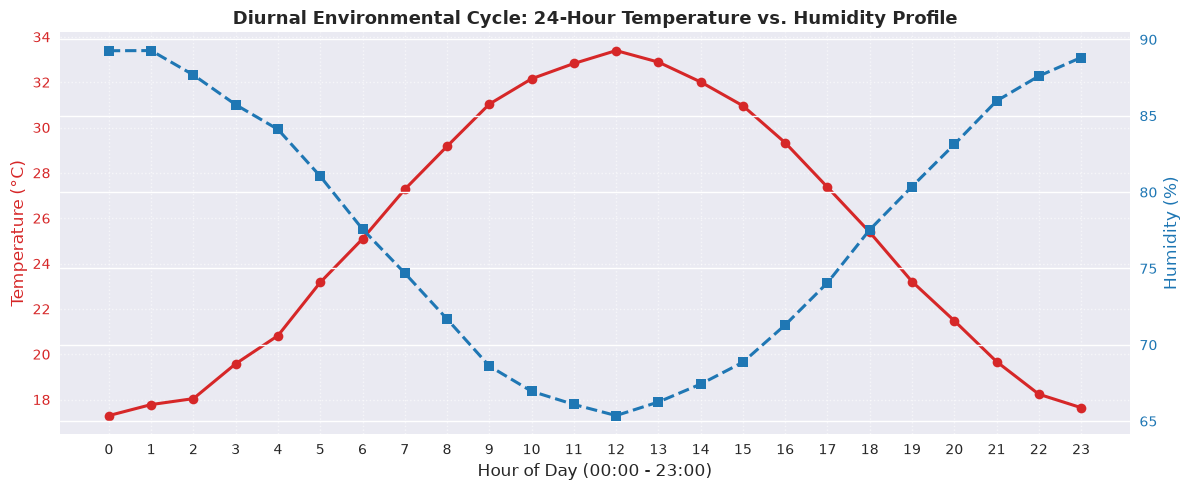

💡 Insight Pola Diurnal:
- Suhu mencapai puncak di siang hari (12:00 - 15:00), berbanding terbalik dengan kelembaban yang mencapai titik minimum.


In [8]:
# 4.1 Diurnal Cycle: Average Temperature & Humidity by Hour of Day
hourly_pattern = df.groupby('hour').agg({
    'temperature_celsius': 'mean',
    'humidity_percent': 'mean',
    'air_quality_aqi': 'mean'
}).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:red'
ax1.set_xlabel('Hour of Day (00:00 - 23:00)', fontsize=12)
ax1.set_ylabel('Temperature (°C)', color=color, fontsize=12)
line1 = ax1.plot(hourly_pattern['hour'], hourly_pattern['temperature_celsius'], color=color, marker='o', linewidth=2.2, label='Temperature (°C)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(0, 24))
ax1.grid(True, linestyle=':', alpha=0.6)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Humidity (%)', color=color, fontsize=12)
line2 = ax2.plot(hourly_pattern['hour'], hourly_pattern['humidity_percent'], color=color, marker='s', linestyle='--', linewidth=2.2, label='Humidity (%)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Diurnal Environmental Cycle: 24-Hour Temperature vs. Humidity Profile', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

print('💡 Insight Pola Diurnal:')
print('- Suhu mencapai puncak di siang hari (12:00 - 15:00), berbanding terbalik dengan kelembaban yang mencapai titik minimum.')


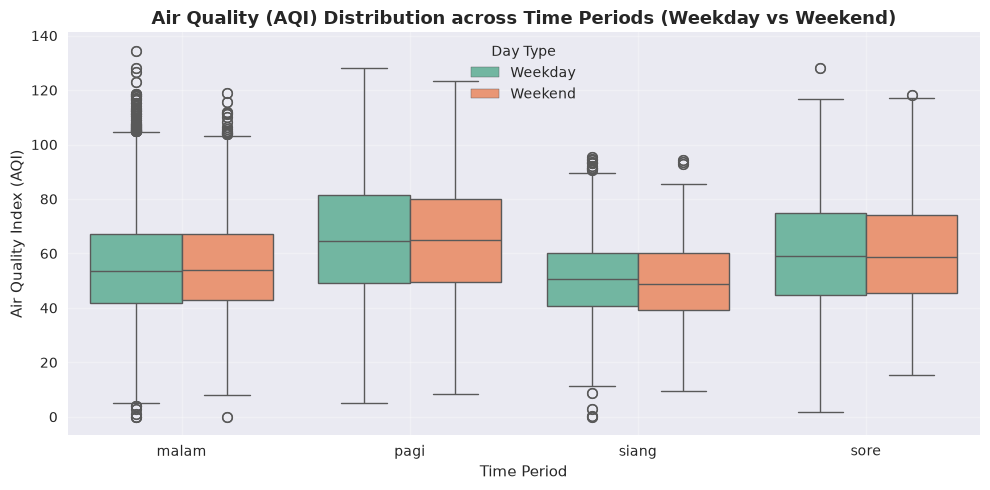

In [9]:
# 4.2 Weekday vs Weekend Comparison
plt.figure(figsize=(10, 5))
df['day_type'] = np.where(df['is_weekend'].isin([1, True]), 'Weekend', 'Weekday')
sns.boxplot(data=df, x='time_period', y='air_quality_aqi', hue='day_type', palette='Set2')
plt.title('Air Quality (AQI) Distribution across Time Periods (Weekday vs Weekend)', fontsize=13, fontweight='bold')
plt.xlabel('Time Period')
plt.ylabel('Air Quality Index (AQI)')
plt.legend(title='Day Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. 🎯 Sensor Performance Monitoring & Health Check
Pemantauan performa sensor (*Sensor Health Check*) mencakup:
- **Uptime (%)**: Persentase sensor dalam status aktif beroperasi.
- **Sensor Drift**: Deviasi rata-rata pembacaan sensor dari rata-rata grup lokasi (*cross-sensor benchmark*).
- **Reliability Score**: Skor komposit kesehatan perangkat sensor.

In [10]:
# 5.1 Perhitungan Sensor Health & Performance Metrics
health_records = []
location_temp_means = df.groupby('location')['temperature_celsius'].mean()

for sensor_id in sorted(df['sensor_id'].unique()):
    sdf = df[df['sensor_id'] == sensor_id]
    total_records = len(sdf)
    active_records = (sdf['status'] == 'active').sum()
    uptime_pct = (active_records / total_records) * 100 if total_records > 0 else 0
    
    sensor_loc = sdf['location'].iloc[0]
    loc_mean = location_temp_means[sensor_loc]
    sensor_mean = sdf['temperature_celsius'].mean()
    drift = abs(sensor_mean - loc_mean)
    
    # Reliability Score (0-100)
    drift_penalty = min(30, drift * 10)
    reliability = max(0, uptime_pct - drift_penalty)
    
    # Maintenance recommendation
    if reliability < 80 or uptime_pct < 95 or drift > 2.5:
        status_rec = '⚠️ RECALIBRATION / CHECK NEEDED'
    else:
        status_rec = '✅ HEALTHY'
        
    health_records.append({
        'Sensor ID': sensor_id,
        'Location': sensor_loc,
        'Total Readings': total_records,
        'Uptime (%)': round(uptime_pct, 2),
        'Avg Temp (°C)': round(sensor_mean, 2),
        'Temp Drift (°C)': round(drift, 2),
        'Reliability Score': round(reliability, 1),
        'Health Status': status_rec
    })

sensor_health_df = pd.DataFrame(health_records)
print('🩺 Sensor Health & Reliability KPI Table:')
display(sensor_health_df)


🩺 Sensor Health & Reliability KPI Table:


,Sensor ID,Location,Total Readings,Uptime (%),Avg Temp (°C),Temp Drift (°C),Reliability Score,Health Status
0,SENSOR_001,Location_B,2884,99.17,25.21,0.00,99.1,✅ HEALTHY
1,SENSOR_002,Location_C,2884,99.03,25.24,0.02,98.8,✅ HEALTHY
2,SENSOR_003,Location_D,2882,98.82,25.26,0.01,98.7,✅ HEALTHY
3,SENSOR_004,Location_E,2880,99.10,25.21,0.07,98.4,✅ HEALTHY
4,SENSOR_005,Location_A,2882,98.82,25.21,0.06,98.3,✅ HEALTHY
5,SENSOR_006,Location_B,2880,99.38,25.20,0.00,99.3,✅ HEALTHY
6,SENSOR_007,Location_C,2882,98.82,25.19,0.02,98.6,✅ HEALTHY
7,SENSOR_008,Location_D,2882,98.75,25.24,0.01,98.6,✅ HEALTHY
8,SENSOR_009,Location_E,2884,98.54,25.35,0.07,97.8,✅ HEALTHY
9,SENSOR_010,Location_A,2884,99.17,25.32,0.06,98.6,✅ HEALTHY


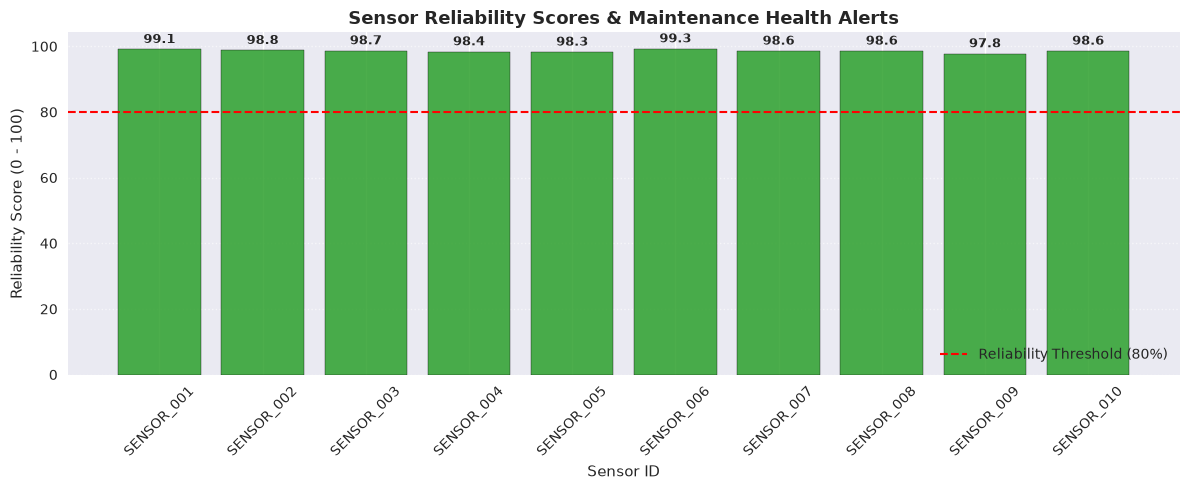

In [11]:
# 5.2 Sensor Reliability Bar Chart
plt.figure(figsize=(12, 5))
colors = ['#2ca02c' if 'HEALTHY' in s else '#d62728' for s in sensor_health_df['Health Status']]
bars = plt.bar(sensor_health_df['Sensor ID'], sensor_health_df['Reliability Score'], color=colors, edgecolor='black', alpha=0.85)
plt.axhline(80, color='red', linestyle='--', linewidth=1.5, label='Reliability Threshold (80%)')
plt.title('Sensor Reliability Scores & Maintenance Health Alerts', fontsize=13, fontweight='bold')
plt.xlabel('Sensor ID')
plt.ylabel('Reliability Score (0 - 100)')
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 6. 📋 Automated Reporting & Executive Summary
Bagian akhir ini mengotomatiskan pembuatan laporan analitis eksekutif yang disimpan langsung ke dalam format Markdown di folder `data/output/`.

In [12]:
# 6.1 Automated Report Generation
report_file = 'data/output/advanced_sensor_analysis_report.md'

top_performing_sensor = sensor_health_df.sort_values('Reliability Score', ascending=False).iloc[0]['Sensor ID']
flagged_sensors = sensor_health_df[sensor_health_df['Health Status'].str.contains('RECALIBRATION')]['Sensor ID'].tolist()

report_md = f"""# 📊 Executive Sensor Analytics & Health Report
**Generated At:** {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}  
**Total Readings Processed:** {len(df):,}  
**Active Sensors Monitored:** {df['sensor_id'].nunique()}  
**Coverage Locations:** {df['location'].nunique()}  

---

## 1. Key Environmental KPI Summary
- **Average Ambient Temperature:** {df['temperature_celsius'].mean():.2f} °C (Min: {df['temperature_celsius'].min():.2f} °C, Max: {df['temperature_celsius'].max():.2f} °C)
- **Average Relative Humidity:** {df['humidity_percent'].mean():.2f} %
- **Average Atmospheric Pressure:** {df['pressure_hpa'].mean():.2f} hPa
- **Air Quality Average AQI:** {df['air_quality_aqi'].mean():.2f}

## 2. Sensor Health & Maintenance Summary
- **Top Performing Sensor:** `{top_performing_sensor}`
- **Sensors Flagged for Inspection/Calibration:** {', '.join([f'`{s}`' for s in flagged_sensors]) if flagged_sensors else 'None (All systems nominal)'}
- **Average Network Reliability Score:** {sensor_health_df['Reliability Score'].mean():.2f} %

## 3. Actionable Recommendations
1. Lakukan inspeksi preventif berkala pada sensor dengan skor reliabilitas < 80%.
2. Kalibrasi ulang sensor yang mengalami thermal drift deviasi > 2.0°C dari rata-rata lokasi.
3. Pertahankan interval sampling 1 jam untuk efisiensi penyimpanan dan kesinambungan time series.
"""

with open(report_file, 'w', encoding='utf-8') as f:
    f.write(report_md)

print(f'✅ Automated report generated successfully at: {report_file}')
from IPython.display import display, Markdown
display(Markdown(report_md))


✅ Automated report generated successfully at: data/output/advanced_sensor_analysis_report.md


# 📊 Executive Sensor Analytics & Health Report
**Generated At:** 2026-09-29 01:45:37  
**Total Readings Processed:** 28,824  
**Active Sensors Monitored:** 10  
**Coverage Locations:** 5  

---

## 1. Key Environmental KPI Summary
- **Average Ambient Temperature:** 25.24 °C (Min: 10.50 °C, Max: 50.00 °C)
- **Average Relative Humidity:** 77.47 %
- **Average Atmospheric Pressure:** 1013.31 hPa
- **Air Quality Average AQI:** 57.57

## 2. Sensor Health & Maintenance Summary
- **Top Performing Sensor:** `SENSOR_006`
- **Sensors Flagged for Inspection/Calibration:** None (All systems nominal)
- **Average Network Reliability Score:** 98.62 %

## 3. Actionable Recommendations
1. Lakukan inspeksi preventif berkala pada sensor dengan skor reliabilitas < 80%.
2. Kalibrasi ulang sensor yang mengalami thermal drift deviasi > 2.0°C dari rata-rata lokasi.
3. Pertahankan interval sampling 1 jam untuk efisiensi penyimpanan dan kesinambungan time series.
